#  Analyse statistique du mode de vie étudiant

## Prétraitement et exploration des données

**Notre problématique :** les habitudes quotidiennes des étudiants sont-elles associées à leur performance académique ?

Dans ce notebook, nous présentons notre exploration, notre vérification de la qualité des données et nos analyses statistiques. Nous ne réalisons pas encore d'entraînement de modèle Machine Learning.

## 1. Importation et chargement des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
DATA_PATH = 'student_lifestyle_dataset.csv'
df = pd.read_csv(DATA_PATH)
print(f'Notre dataset contient {df.shape[0]} lignes et {df.shape[1]} colonnes.')
df.head()

Notre dataset contient 2000 lignes et 8 colonnes.


,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level
0,1,6.9,3.8,8.7,2.8,1.8,2.99,Moderate
1,2,5.3,3.5,8.0,4.2,3.0,2.75,Low
2,3,5.1,3.9,9.2,1.2,4.6,2.67,Low
3,4,6.5,2.1,7.2,1.7,6.5,2.88,Moderate
4,5,8.1,0.6,6.5,2.2,6.6,3.51,High


## 2. Présentation des données

Nous avons 2 000 étudiants et 8 variables. Les variables horaires représentent les activités quotidiennes. `GPA` représente la performance académique et `Stress_Level` le niveau de stress.

In [2]:
df.info()
display(df.describe(include='all').T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Student_ID                       2000 non-null   int64  
 1   Study_Hours_Per_Day              2000 non-null   float64
 2   Extracurricular_Hours_Per_Day    2000 non-null   float64
 3   Sleep_Hours_Per_Day              2000 non-null   float64
 4   Social_Hours_Per_Day             2000 non-null   float64
 5   Physical_Activity_Hours_Per_Day  2000 non-null   float64
 6   GPA                              2000 non-null   float64
 7   Stress_Level                     2000 non-null   object 
dtypes: float64(6), int64(1), object(1)
memory usage: 125.1+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,2000.0,NaN,NaN,NaN,1000.5,577.494589,1.0,500.75,1000.5,1500.25,2000.0
Study_Hours_Per_Day,2000.0,NaN,NaN,NaN,7.4758,1.423888,5.0,6.3,7.4,8.7,10.0
Extracurricular_Hours_Per_Day,2000.0,NaN,NaN,NaN,1.9901,1.155855,0.0,1.0,2.0,3.0,4.0
Sleep_Hours_Per_Day,2000.0,NaN,NaN,NaN,7.50125,1.460949,5.0,6.2,7.5,8.8,10.0
Social_Hours_Per_Day,2000.0,NaN,NaN,NaN,2.70455,1.688514,0.0,1.2,2.6,4.1,6.0
Physical_Activity_Hours_Per_Day,2000.0,NaN,NaN,NaN,4.3283,2.51411,0.0,2.4,4.1,6.1,13.0
GPA,2000.0,NaN,NaN,NaN,3.11596,0.298674,2.24,2.9,3.11,3.33,4.0
Stress_Level,2000,3,High,1029,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Vérification de la qualité des données

Nous vérifions les valeurs manquantes, les doublons et les identifiants avant de commencer les analyses.

In [3]:
print('Valeurs manquantes par colonne :')
display(df.isna().sum().to_frame('nombre'))
print('Nombre de doublons exacts :', df.duplicated().sum())
print('Nombre d’identifiants uniques :', df['Student_ID'].nunique())
print('Modalités de Stress_Level :', df['Stress_Level'].unique())

Valeurs manquantes par colonne :


,nombre
Student_ID,0
Study_Hours_Per_Day,0
Extracurricular_Hours_Per_Day,0
Sleep_Hours_Per_Day,0
Social_Hours_Per_Day,0
Physical_Activity_Hours_Per_Day,0
GPA,0
Stress_Level,0


Nombre de doublons exacts : 0
Nombre d’identifiants uniques : 2000
Modalités de Stress_Level : ['Moderate' 'Low' 'High']


### Notre constat sur la qualité

Nous constatons qu'il n'y a aucune valeur manquante et aucun doublon exact. Nous n'avons donc pas besoin d'effectuer une imputation. Cette base est simple à nettoyer, ce qui nous permet de nous concentrer sur l'analyse statistique.

## 4. Statistiques descriptives

In [4]:
numeric_cols = ['Study_Hours_Per_Day','Extracurricular_Hours_Per_Day','Sleep_Hours_Per_Day','Social_Hours_Per_Day','Physical_Activity_Hours_Per_Day','GPA']
display(df[numeric_cols].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Study_Hours_Per_Day,2000.0,7.476,1.424,5.00,6.3,7.40,8.70,10.0
Extracurricular_Hours_Per_Day,2000.0,1.990,1.156,0.00,1.0,2.00,3.00,4.0
Sleep_Hours_Per_Day,2000.0,7.501,1.461,5.00,6.2,7.50,8.80,10.0
Social_Hours_Per_Day,2000.0,2.705,1.689,0.00,1.2,2.60,4.10,6.0
Physical_Activity_Hours_Per_Day,2000.0,4.328,2.514,0.00,2.4,4.10,6.10,13.0
GPA,2000.0,3.116,0.299,2.24,2.9,3.11,3.33,4.0


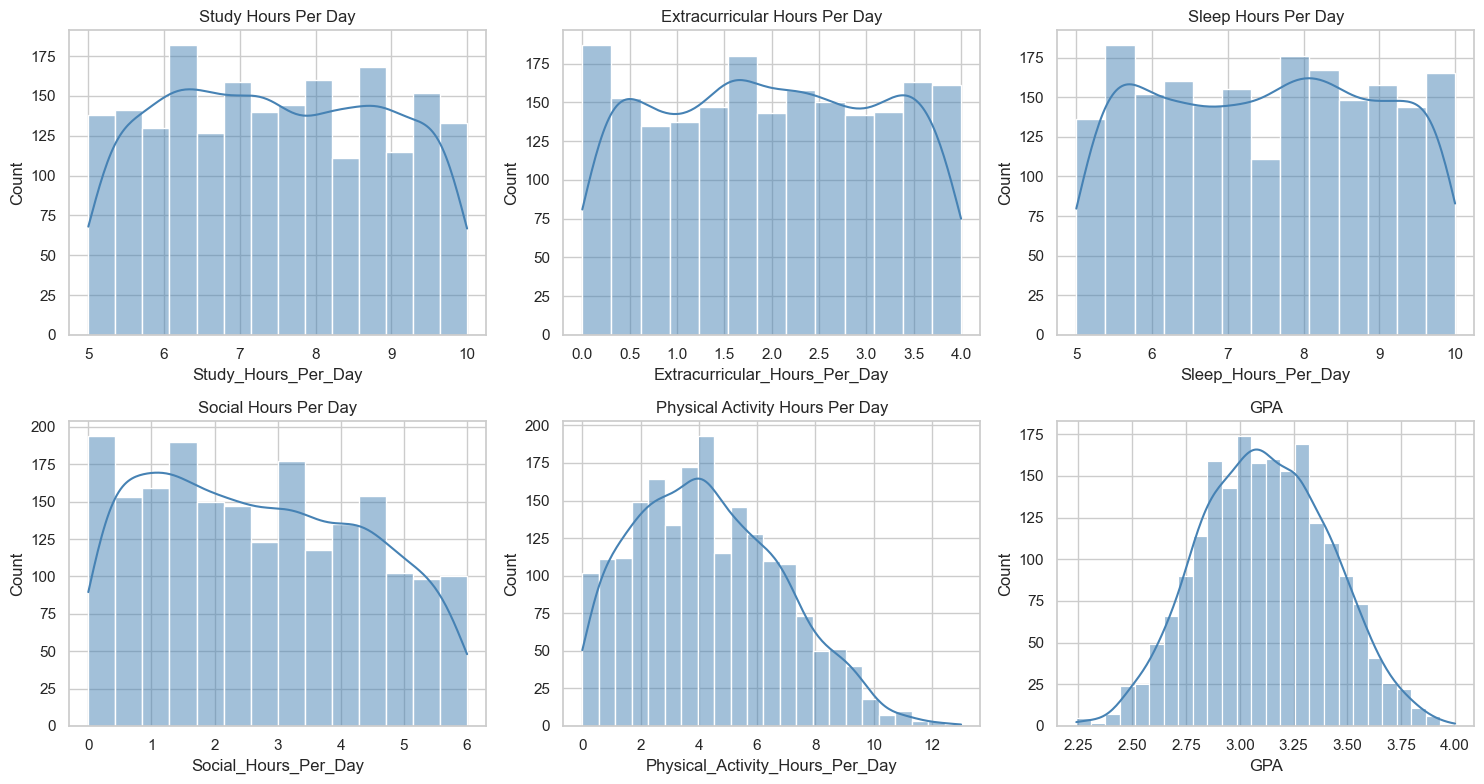

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue')
    ax.set_title(col.replace('_',' '))
plt.tight_layout()
plt.show()

Nous observons que le GPA moyen est de **3,12**. Les étudiants consacrent en moyenne **7,48 heures aux études**, **7,50 heures au sommeil** et **4,33 heures à l'activité physique** par jour.

## 5. Vérification de la répartition des 24 heures

Nous vérifions si les cinq variables horaires représentent ensemble une journée complète.

In [6]:
time_cols = ['Study_Hours_Per_Day','Extracurricular_Hours_Per_Day','Sleep_Hours_Per_Day','Social_Hours_Per_Day','Physical_Activity_Hours_Per_Day']
df['Total_Hours'] = df[time_cols].sum(axis=1)
display(df['Total_Hours'].describe())
print('Nombre de lignes dont le total est différent de 24 :', (df['Total_Hours'] != 24).sum())

count    2.000000e+03
mean     2.400000e+01
std      1.575252e-15
min      2.400000e+01
25%      2.400000e+01
50%      2.400000e+01
75%      2.400000e+01
max      2.400000e+01
Name: Total_Hours, dtype: float64

Nombre de lignes dont le total est différent de 24 : 393


Nous constatons que le total est égal à 24 heures pour les 2 000 étudiants. Les variables horaires sont donc liées entre elles : augmenter une activité réduit nécessairement le temps disponible pour une autre. Cette régularité nous conduit aussi à rester prudents sur l'origine et la construction du dataset.

## 6. Analyse du niveau de stress

,nombre
Stress_Level,
High,1029
Moderate,674
Low,297


C:\Users\DELL\AppData\Local\Temp\ipykernel_24540\1091828648.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Stress_Level', order=['Low','Moderate','High'], palette='Set2')


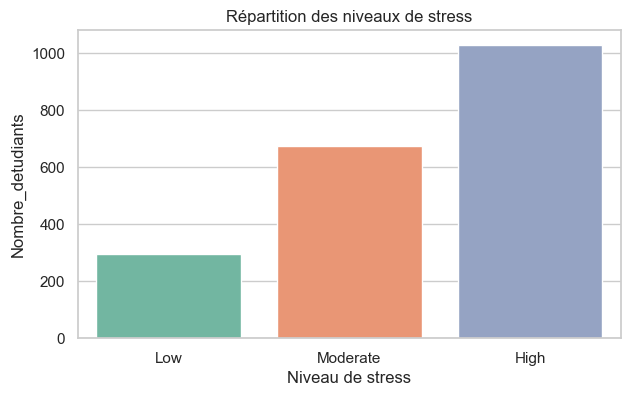

In [7]:
stress_counts = df['Stress_Level'].value_counts()
display(stress_counts.to_frame('nombre'))

plt.figure(figsize=(7,4))
sns.countplot(data=df, x='Stress_Level', order=['Low','Moderate','High'], palette='Set2')
plt.title('Répartition des niveaux de stress')
plt.xlabel('Niveau de stress')
plt.ylabel('Nombre_detudiants')
plt.show()

,count,mean,median,std
Stress_Level,,,,
Low,297,2.817,2.82,0.215
Moderate,674,3.025,3.02,0.221
High,1029,3.262,3.27,0.275


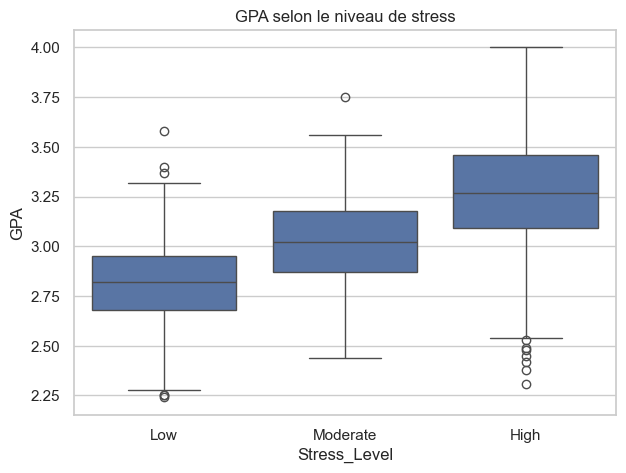

In [8]:
stress_gpa = df.groupby('Stress_Level')['GPA'].agg(['count','mean','median','std']).reindex(['Low','Moderate','High'])
display(stress_gpa.round(3))

plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='Stress_Level', y='GPA', order=['Low','Moderate','High'])
plt.title('GPA selon le niveau de stress')
plt.show()

Nous obtenons un GPA moyen de **2,817** pour le stress faible, **3,025** pour le stress modéré et **3,262** pour le stress élevé. Ce résultat est contre-intuitif. Nous ne pouvons donc pas conclure que le stress améliore les résultats ; nous le présentons comme un résultat particulier de cette base et comme une limite à discuter.

## 7. Corrélations avec le GPA

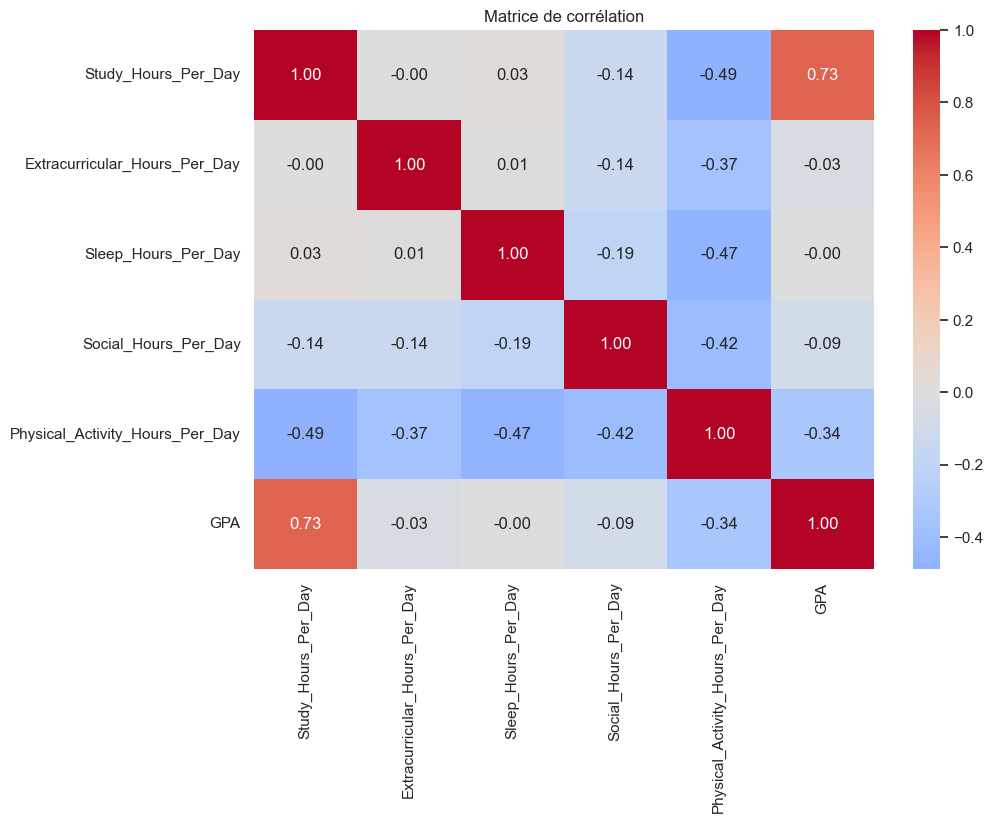

Corrélations avec le GPA :


,corrélation
GPA,1.000
Study_Hours_Per_Day,0.734
Sleep_Hours_Per_Day,-0.004
Extracurricular_Hours_Per_Day,-0.032
Social_Hours_Per_Day,-0.086
Physical_Activity_Hours_Per_Day,-0.341


In [9]:
corr = df[numeric_cols].corr()
plt.figure(figsize=(10,7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matrice de corrélation')
plt.show()
print('Corrélations avec le GPA :')
display(corr['GPA'].sort_values(ascending=False).to_frame('corrélation').round(3))

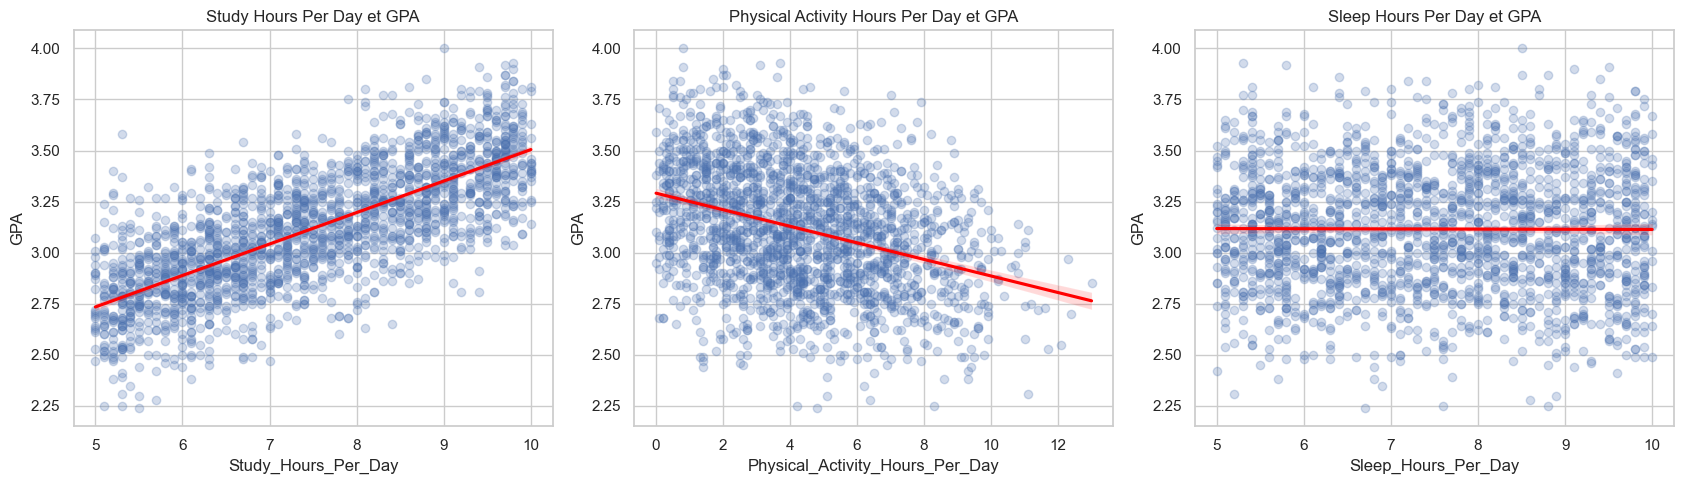

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17,5))
for ax, col in zip(axes, ['Study_Hours_Per_Day','Physical_Activity_Hours_Per_Day','Sleep_Hours_Per_Day']):
    sns.regplot(data=df, x=col, y='GPA', scatter_kws={'alpha':.25}, line_kws={'color':'red'}, ax=ax)
    ax.set_title(col.replace('_',' ') + ' et GPA')
plt.tight_layout()
plt.show()

Nous observons les corrélations suivantes avec le GPA : **0,734** pour les heures d'étude, **−0,341** pour l'activité physique, **−0,086** pour les heures sociales, **−0,032** pour les activités extrascolaires et **−0,004** pour le sommeil.

Nous interprétons ces valeurs comme des associations. Une corrélation ne prouve pas qu'une variable cause directement une variation du GPA.

## 8. Valeurs aberrantes avec la méthode IQR

In [11]:
def iqr_report(series):
    q1, q3 = series.quantile([.25,.75])
    iqr = q3-q1
    low, high = q1-1.5*iqr, q3+1.5*iqr
    n = ((series<low)|(series>high)).sum()
    return q1, q3, low, high, n

for col in numeric_cols:
    q1,q3,low,high,n = iqr_report(df[col])
    print(f'{col}: {n} valeur(s) potentiellement aberrante(s), bornes [{low:.2f}, {high:.2f}]')

Study_Hours_Per_Day: 0 valeur(s) potentiellement aberrante(s), bornes [2.70, 12.30]
Extracurricular_Hours_Per_Day: 0 valeur(s) potentiellement aberrante(s), bornes [-2.00, 6.00]
Sleep_Hours_Per_Day: 0 valeur(s) potentiellement aberrante(s), bornes [2.30, 12.70]
Social_Hours_Per_Day: 0 valeur(s) potentiellement aberrante(s), bornes [-3.15, 8.45]
Physical_Activity_Hours_Per_Day: 5 valeur(s) potentiellement aberrante(s), bornes [-3.15, 11.65]
GPA: 4 valeur(s) potentiellement aberrante(s), bornes [2.25, 3.98]


Nous utilisons l'IQR pour repérer les valeurs extrêmes, mais nous ne supprimons pas automatiquement ces observations. Une valeur aberrante peut être une erreur, mais elle peut aussi représenter un étudiant ayant réellement une valeur élevée ou faible.

## 9. Conclusion

Nous avons analysé 2 000 étudiants et vérifié que la base ne contient aucune valeur manquante ni aucun doublon exact. Les heures d'étude présentent la plus forte association avec le GPA, avec une corrélation de **0,734**.

Nous avons aussi constaté que les cinq variables horaires totalisent exactement 24 heures pour chaque étudiant et que la relation entre le stress et le GPA est contre-intuitive. Ces observations nous obligent à rester prudents et à ne pas généraliser les résultats à tous les étudiants.

Ce dataset est adapté à l'apprentissage des outils statistiques. Une étude Machine Learning pourrait être réalisée plus tard, dans un travail séparé, après vérification de la manière dont les variables ont été construites.